# 01 | 過去課題を継承したAI異常検知・巡回計画の統計的評価
このNotebookは**2D運動学によるアルゴリズム評価専用**です。ここでの走行距離・衝突試行はGenesis剛体物理の測定値ではありません。**本編の3D物理動作は02**で実行します。

第1回講義録：システム工学、MLOps／RobOps、シミュレーションと実機の差。第6回：OSS・再現性・貢献。
アルゴリズムはLiu et al.のIsolation Forest、Hart et al.のA*を参考に構成。

In [1]:
%pip -q install 'numpy<3' 'pandas>=2,<3' 'scikit-learn>=1.3,<2' 'matplotlib>=3.7,<4' 'opencv-python-headless>=4.8,<5' imageio-ffmpeg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 23.5 MB/s eta 0:00:00


In [2]:
%%writefile pai_patrol.py
"""Physical AI: risk-aware mobile inspection robot (Colab, reproducible demo).

Simulation fidelity: 2-D occupancy grid + differential-drive/unicycle kinematics,
not a ROS/Gazebo or hardware experiment. Remote sensors are synthetic, not measured.
Anomaly ground truth is private to the environment and used only for scoring.
"""
from __future__ import annotations
from dataclasses import dataclass
from pathlib import Path
from typing import Optional
import heapq
import math
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_fscore_support

STATIONS = {
    'A': (1.5, 7.4),
    'B': (3.5, 6.1),
    'C': (8.6, 7.0),
    'D': (10.5, 3.4),
    'E': (6.5, 1.3),
    'F': (2.0, 3.6),
}
BASE = (1.0, 1.0)
OBSTACLES = [(3.9, 2.1, 5.0, 4.8), (6.5, 4.1, 8.0, 5.7), (8.1, 1.5, 9.0, 3.2)]
WIDTH, HEIGHT = 12.0, 9.0
FEATURES = ['temperature_C', 'vibration_mm_s', 'current_A', 'sound_dB']
STATION_KEYS = list(STATIONS)
MEANS = np.array([[35 + i*1.2, 2.1+i*.08, 5+i*.13, 51+i*.45] for i in range(len(STATIONS))], dtype = float)
STDS = np.array([1.6, .35, .26, 2.1])
FAULT_SHIFT = np.array([9.0, 1.8, 1.2, 9.0])

@dataclass(frozen = True)
class Config:
    dt: float = 0.10
    horizon: float = 150.0
    max_speed: float = 0.68
    max_turn: float = 2.4
    robot_radius: float = 0.25
    grid_res: float = 0.25
    remote_period: float = 2.0
    camera_fps: int = 10
    camera_stride: int = 1
    risk_gate: float = 1.10
    revisit_after: float = 15.0

CFG = Config()

class FloorMap:
    def __init__(self, cfg = CFG):
        self.cfg = cfg
        self.nx = int(round(WIDTH/cfg.grid_res))
        self.ny = int(round(HEIGHT/cfg.grid_res))
        self.grid = np.zeros((self.ny, self.nx), dtype = np.uint8)
        for gy in range(self.ny):
            for gx in range(self.nx):
                x, y = self.from_cell((gx, gy))
                if self.blocked(x, y, margin = cfg.robot_radius+0.09):
                    self.grid[gy, gx] = 1
        assert all(self.grid[self.to_cell(pt)[1], self.to_cell(pt)[0]] == 0 for pt in [BASE, *STATIONS.values()]), 'Station collides with inflated obstacles'
    def blocked(self, x, y, margin = 0.):
        if x<margin or y<margin or x>WIDTH-margin or y>HEIGHT-margin:
            return True
        return any(a-margin <= x <= c+margin and b-margin <= y <= d+margin for a, b, c, d in OBSTACLES)
    def to_cell(self, xy):
        return (min(self.nx-1,max(0,int(xy[0]/self.cfg.grid_res))),
                min(self.ny-1, max(0, int(xy[1]/self.cfg.grid_res))))
    def from_cell(self, cell):
        return ((cell[0]+.5)*self.cfg.grid_res, (cell[1]+.5)*self.cfg.grid_res)
    def line_clear(self, a, b):
        d = math.dist(a, b)
        for u in np.linspace(0, 1, max(2, int(math.ceil(d/0.09)))):
            x = a[0]+(b[0]-a[0])*u
            y = a[1]+(b[1]-a[1])*u
            if self.blocked(x, y, self.cfg.robot_radius+0.04):
                return False
        return True
    def plan(self, start, end):
        s = self.to_cell(start)
        g = self.to_cell(end)
        if s == g or self.line_clear(start, end):
            return [tuple(end)]
        h = lambda p: math.hypot(p[0]-g[0], p[1]-g[1])
        heap = [(h(s), 0., s)]
        best = {s:0.}
        parent = {}
        found = False
        dirs = [(dx, dy) for dx in (-1, 0, 1) for dy in (-1, 0, 1) if dx or dy]
        while heap:
            _, cost, u = heapq.heappop(heap)
            if cost>best.get(u, float('inf'))+1e-8:
                continue
            if u == g:
                found = True
                break
            for dx, dy in dirs:
                v = (u[0]+dx, u[1]+dy)
                if not (0 <= v[0]<self.nx and 0 <= v[1]<self.ny) or self.grid[v[1], v[0]]:
                    continue
                if dx and dy and (self.grid[u[1], v[0]] or self.grid[v[1], u[0]]):
                    continue
                nc = cost+math.hypot(dx, dy)
                if nc<best.get(v, float('inf')):
                    best[v] = nc
                    parent[v] = u
                    heapq.heappush(heap, (nc+h(v), nc, v))
        if not found:
            raise RuntimeError(f'Route unreachable: {start} -> {end}')
        path = [g]
        while path[-1] != s:
            path.append(parent[path[-1]])
        path.reverse()
        pts = [tuple(start)]+[self.from_cell(pt) for pt in path[1:-1]]+[tuple(end)]
        # Greedy line-of-sight waypoint reduction (collision checked, inflated obstacles)
        out = []
        i = 0
        while i<len(pts)-1:
            j = len(pts)-1
            while j>i+1 and not self.line_clear(pts[i], pts[j]):
                j -= 1
            out.append(pts[j])
            i = j
        return out
    def distance(self, start, end):
        p = [tuple(start)]+self.plan(start, end)
        return sum(math.dist(p[i], p[i+1]) for i in range(len(p)-1))

@dataclass(frozen = True)
class Fault:
    station: str
    onset: float
    severity: float

@dataclass(frozen = True)
class Scenario:
    seed: int
    faults: tuple[Fault, ...]


def make_scenario(seed):
    rng = np.random.default_rng(int(seed))
    keys = rng.choice(STATION_KEYS, size = 2, replace = False)
    return Scenario(int(seed),(Fault(str(keys[0]),0.0,float(rng.uniform(.95,1.45))),
                               Fault(str(keys[1]), float(rng.choice([12., 18., 24.])), float(rng.uniform(1.05, 1.55)))))


def telemetry(scenario, station, t, mode = 'remote', replicate = 0):
    """Synthetic sensor. Policy receives sensor values only, never `scenario.faults`."""
    idx = STATION_KEYS.index(station)
    # Deterministic per (seed, equipment, time-window, mode, replicate).
    tick = max(0, int(t//(CFG.remote_period if mode == 'remote' else 1.0)))
    ss = np.random.SeedSequence([scenario.seed, idx, tick, 0 if mode == 'remote' else 1, int(replicate)])
    rng = np.random.default_rng(ss)
    noise = 1.17 if mode == 'remote' else .40
    x = MEANS[idx]+rng.normal(size = 4)*STDS*noise
    for fault in scenario.faults:
        if station == fault.station and t >= fault.onset:
            x = x+FAULT_SHIFT*fault.severity
    return x

class Detector:
    def __init__(self, seed = 2026):
        rng = np.random.default_rng(seed)
        normal = rng.normal(size = (3500, 4))*1.17
        # Only NORMAL observations in training. Ground truth of evaluation faults unseen.
        self.model = IsolationForest(n_estimators = 120, max_samples = 256, random_state = seed, n_jobs = -1)
        self.model.fit(normal)
        vr = rng.normal(size = (3000, 4))*1.17
        vl = rng.normal(size = (3000, 4))*.40
        rs = -self.model.score_samples(vr)
        ls = -self.model.score_samples(vl)
        self.remote_threshold = float(np.quantile(rs, .99))
        self.local_threshold = float(np.quantile(ls, .995))
        self.reference_75 = float(np.quantile(rs, .75))
        self.spread = max(.015, self.remote_threshold-self.reference_75)
    def features(self, x, station):
        idx = STATION_KEYS.index(station)
        return ((np.asarray(x)-MEANS[idx])/STDS).reshape(1, -1)
    def anomaly(self, x, station):
        return float(-self.model.score_samples(self.features(x, station))[0])
    def remote_risk(self, x, station):
        a = self.anomaly(x, station)
        return float(np.clip((a-self.reference_75)/self.spread, 0., 3.0))
    def onsite_flag(self, scenario, station, t):
        # independent repeat-measurement median reduces occasional false alarms
        scores = [self.anomaly(telemetry(scenario, station, t, mode = 'local', replicate = k), station) for k in range(3)]
        med = float(np.median(scores))
        return med>self.local_threshold, med

@dataclass
class PatrolResult:
    policy: str
    scenario: Scenario
    metrics: dict
    visits: list
    trajectory: list
    events: list
    remote_history: list

class Patrol:
    def __init__(self, scenario, detector, policy = 'adaptive', cfg = CFG, floor = None):
        if policy not in ('adaptive','nearest'):
            raise ValueError('policy must be adaptive or nearest')
        self.scenario = scenario
        self.detector = detector
        self.policy = policy
        self.cfg = cfg
        self.floor = floor if floor is not None else FloorMap(cfg)
        self.pos = np.array(BASE, dtype = float)
        self.heading = math.pi/2
        self.t = 0.
        self.distance = 0.
        self.collisions = 0
        self.replans = 0
        self.route = []
        self.target = None
        self.waypoint = 0
        self.visits = []
        self.events = []
        self.history = []
        self.trajectory = []
        self.last_visit = {k:-1e9 for k in STATION_KEYS}
        self.visit_counts = {k:0 for k in STATION_KEYS}
        self.target_start = -1e9
        self.consecutive_alarm = {k:0 for k in STATION_KEYS}
        self.remote_risks = {k:0. for k in STATION_KEYS}
        self.active_alarm = {k:False for k in STATION_KEYS}
        self.detections = {}
        self.flagged_stations = set()
        self.fp_count = 0
        self.next_remote = 0.
        self.finished = False
    def observe_remote(self):
        risks = {}
        for key in STATION_KEYS:
            observed = telemetry(self.scenario, key, self.t,'remote')
            risk = self.detector.remote_risk(observed, key)
            self.remote_risks[key] = .35*self.remote_risks[key]+.65*risk
            self.consecutive_alarm[key] = (self.consecutive_alarm[key]+1 if self.remote_risks[key] >= self.cfg.risk_gate else 0)
            risks[key] = self.remote_risks[key]
        self.history.append({'t':round(self.t, 1), **risks})
    def options(self):
        outstanding = [k for k in STATION_KEYS if self.last_visit[k]<0]
        if self.policy == 'nearest':
            return outstanding
        alerts=[k for k in STATION_KEYS if self.consecutive_alarm[k]>=2
                and k not in self.flagged_stations and self.visit_counts[k]<2
                and (self.t-self.last_visit[k])>self.cfg.revisit_after]
        return sorted(set(outstanding+alerts))
    def choose_target(self):
        choices = self.options()
        if not choices:
            return 'HOME'
        distances = {k:self.floor.distance(self.pos, STATIONS[k]) for k in choices}
        if self.policy == 'nearest':
            return min(choices, key = lambda k:(distances[k], k))
        # Alarm priority competes with travel cost; no hidden ground truth labels used.
        return max(choices,key=lambda k:(3.5*self.remote_risks[k]-.30*distances[k]
                                         + (1.8 if self.last_visit[k]<0 else 0), -distances[k]))
    def set_target(self, k):
        if self.target == k:
            return
        self.target = k
        self.replans += 1
        self.target_start = self.t
        end = BASE if k == 'HOME' else STATIONS[k]
        self.route = self.floor.plan(self.pos, end)
        self.waypoint = 0
        self.events.append({'t':round(self.t, 1),'kind':'reroute','station':k})
    def arrive(self):
        k = self.target
        if k == 'HOME':
            self.finished = True
            self.events.append({'t':round(self.t, 1),'kind':'home','station':'HOME'})
            return
        flagged, score = self.detector.onsite_flag(self.scenario, k, self.t)
        fault = next((f for f in self.scenario.faults if f.station == k and self.t >= f.onset), None)
        is_fault = fault is not None
        if flagged:
            self.flagged_stations.add(k)
        if flagged and is_fault:
            self.detections.setdefault(k, self.t)
        if flagged and not is_fault:
            self.fp_count += 1
        self.last_visit[k] = self.t
        self.visit_counts[k] += 1
        row={'t':round(self.t,1),'station':k,'flagged':bool(flagged),'fault_active':bool(is_fault),
             'anomaly_score':score,'risk':self.remote_risks[k]}
        self.visits.append(row)
        self.events.append({'t':round(self.t,1),'kind':'inspect','station':k,
                            'flagged':bool(flagged),'fault_active':bool(is_fault)})
        self.target = None
        self.route = []
    def step(self):
        if self.finished:
            return
        if self.t+1e-8 >= self.next_remote:
            self.observe_remote()
            self.next_remote += self.cfg.remote_period
            if self.policy == 'adaptive' and self.target not in (None,'HOME') and self.t-self.target_start>6.:
                # A fresh strong remote alarm can interrupt a low-risk current route.
                opts = self.options()
                serious = [k for k in opts if k != self.target and self.consecutive_alarm[k] >= 2 and self.remote_risks[k]>self.remote_risks.get(self.target, 0)+1.05]
                if serious:
                    best = max(serious, key = lambda k:self.remote_risks[k]-.18*self.floor.distance(self.pos, STATIONS[k]))
                    self.set_target(best)
        if self.target is None:
            self.set_target(self.choose_target())
        goal = np.asarray(BASE if self.target == 'HOME' else STATIONS[self.target])
        if math.dist(self.pos, goal)<.37:
            self.arrive()
        else:
            if self.waypoint >= len(self.route):
                self.route = self.floor.plan(self.pos, goal)
                self.waypoint = 0
                self.replans += 1
            wp = np.asarray(self.route[self.waypoint])
            if np.linalg.norm(wp-self.pos)<.22 and self.waypoint<len(self.route)-1:
                self.waypoint += 1
                wp = np.asarray(self.route[self.waypoint])
            desired = math.atan2(wp[1]-self.pos[1], wp[0]-self.pos[0])
            delta = (desired-self.heading+math.pi)%(2*math.pi)-math.pi
            omega = np.clip(3.0*delta, -self.cfg.max_turn, self.cfg.max_turn)
            # Differential drive kinematics: v=(r/2)(wr+wl), w=(r/L)(wr-wl)
            v = self.cfg.max_speed * max(.05, 1.0-min(1.0, abs(delta)/1.3))
            # Convert commanded twist to actual left/right wheel rates, then integrate.
            wheel_radius, wheel_separation = .085, .36
            wheel_l = (v-.5*wheel_separation*omega)/wheel_radius
            wheel_r = (v+.5*wheel_separation*omega)/wheel_radius
            v_eff = .5*wheel_radius*(wheel_r+wheel_l)
            omega_eff = wheel_radius*(wheel_r-wheel_l)/wheel_separation
            next_heading = (self.heading+omega_eff*self.cfg.dt+math.pi)%(2*math.pi)-math.pi
            proposed = self.pos+v_eff*self.cfg.dt*np.array([math.cos(next_heading), math.sin(next_heading)])
            if self.floor.blocked(*proposed, margin = self.cfg.robot_radius+.01):
                self.collisions += 1
                self.route = self.floor.plan(self.pos, goal)
                self.waypoint = 0
                self.replans += 1
                v = 0.0
            else:
                self.pos = proposed
                self.distance += v*self.cfg.dt
            self.heading = next_heading
        self.t += self.cfg.dt
        self.trajectory.append((self.t,float(self.pos[0]),float(self.pos[1]),float(self.heading),self.target or '-',
                                float(max(self.remote_risks.values())), len(self.detections)))
    def run(self):
        nsteps = int(self.cfg.horizon/self.cfg.dt)
        for _ in range(nsteps):
            if self.finished:
                break
            self.step()
        fault_count = len(self.scenario.faults)
        delays = []
        for f in self.scenario.faults:
            found = self.detections.get(f.station)
            # Missed events receive the horizon penalty (censored observation).
            delays.append((self.cfg.horizon-f.onset if found is None else max(0, found-f.onset), f.severity))
        weight = sum(sev for _, sev in delays)
        weighted = sum(d*sev for d, sev in delays)/weight if weight else float('nan')
        inspected = len([k for k in STATION_KEYS if self.last_visit[k] >= 0])
        metrics={'seed':self.scenario.seed,'policy':self.policy,'detected':len(self.detections),
                 'faults':fault_count,'recall':len(self.detections)/fault_count,
                 'false_alarm_inspections':self.fp_count,
                 'weighted_detection_delay_s':weighted,'distance_m':self.distance,
                 'elapsed_s':self.t,'coverage':inspected/len(STATION_KEYS),
                 'replans':self.replans,'collision_attempts':self.collisions,
                 'home_reached':self.finished}
        return PatrolResult(self.policy, self.scenario, metrics, self.visits, self.trajectory, self.events, self.history)


def evaluate(seed_list = range(30, 50), detector = None, cfg = CFG, verbose = True):
    detector = detector if detector is not None else Detector()
    floor = FloorMap(cfg)
    results = []
    scenarios = []
    for seed in seed_list:
        s = make_scenario(seed)
        scenarios.append(s)
        for policy in ('nearest','adaptive'):
            results.append(Patrol(s, detector, policy, cfg, floor).run())
    dataframe = pd.DataFrame([r.metrics for r in results])
    paired = dataframe.pivot(index = 'seed', columns = 'policy')
    differences=pd.DataFrame({
        'delay_improvement_s':paired[('weighted_detection_delay_s','nearest')]-paired[('weighted_detection_delay_s','adaptive')],
        'recall_improvement':paired[('recall','adaptive')]-paired[('recall','nearest')],
        'extra_distance_m':paired[('distance_m','adaptive')]-paired[('distance_m','nearest')],
    })
    if verbose:
        print('Policies: nearest = distance-only patrol; adaptive = AI-risk priority patrol')
        print('Note: training/calibration and evaluation scenarios are separate.')
        print(dataframe.groupby('policy')[['recall','weighted_detection_delay_s','distance_m','coverage','collision_attempts','false_alarm_inspections']].mean().round(2).to_string())
        print('Paired mean differences (positive delay_improvement is better):')
        print(differences.mean().round(2).to_string())
    return dataframe, differences, results


def smoke_test():
    floor = FloorMap()
    d = Detector()
    for k, p in STATIONS.items():
        assert floor.plan(BASE, p), k
    scenario = make_scenario(42)
    v = Patrol(scenario, d,'adaptive', floor = floor).run()
    assert 0 <= v.metrics['recall'] <= 1
    assert len(v.trajectory)>40
    assert not np.isnan(v.metrics['weighted_detection_delay_s'])
    assert v.metrics['elapsed_s'] <= CFG.horizon+1e-6
    print('smoke test OK:', {k:round(v.metrics[k], 2) if isinstance(v.metrics[k], float) else v.metrics[k] for k in ['recall','distance_m','elapsed_s','coverage','home_reached','collision_attempts']})
    return v

if __name__ == '__main__':
    smoke_test()
    evaluate(range(42, 46))


Writing pai_patrol.py


In [3]:
%%writefile pai_visuals.py
"""Visuals and MP4 rendering for Physical AI patrol demo.
All overlays are in English to avoid missing Japanese fonts on free Colab.
"""
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import imageio.v2 as imageio
from IPython.display import display, Video
from pai_patrol import BASE, WIDTH, HEIGHT, STATIONS, STATION_KEYS, OBSTACLES, CFG

CANVAS_W, CANVAS_H = 580, 530
BLUE = (205, 140, 55)
RED = (70, 80, 228)
GREEN = (65, 170, 100)
INK = (34, 37, 45)

def risk_chart(result, station_order = STATION_KEYS):
    h = pd.DataFrame(result.remote_history)
    fig, ax = plt.subplots(figsize = (10, 3.6))
    for name in station_order:
        ax.plot(h['t'], h[name], label = name, linewidth = 1.5)
    ax.axhline(CFG.risk_gate, ls = '--', color = 'black', alpha = .5, label = 'alert threshold')
    ax.set(xlabel='Time (s)',ylabel='Remote AI risk (normalized)',title=f'{result.policy}: remote telemetry -> anomaly risk')
    ax.legend(ncol = 7, loc = 'upper center', bbox_to_anchor = (.5, -.2))
    ax.grid(alpha = .2)
    fig.tight_layout()
    return fig

def benchmark_charts(df, deltas):
    metrics=[('recall','Event detection recall','higher'),('weighted_detection_delay_s','Weighted detection delay (s)','lower'),
             ('distance_m','Travel distance (m)','lower')]
    mean = df.groupby('policy').mean(numeric_only = True)
    fig, axs = plt.subplots(1, 3, figsize = (12, 3.8))
    for ax, (col, title, better) in zip(axs, metrics):
        vals = [float(mean.loc['nearest', col]), float(mean.loc['adaptive', col])]
        bars = ax.bar(['Distance-only','AI-adaptive'], vals, color = ['#9ca3af','#2563eb'])
        ax.set_title(title, fontsize = 10)
        ax.set_ylim(bottom = 0)
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2,v,f'{v:.2f}',ha='center',va='bottom',fontsize=9)
        ax.tick_params(axis = 'x', labelrotation = 17)
    fig.suptitle(f'Paired evaluation across {len(deltas)} seeded scenarios (simulation)',fontsize=12)
    fig.tight_layout()
    return fig

def _text(img, text, x, y, size = .54, color = INK, weight = 1):
    cv2.putText(img, str(text), (int(x), int(y)), cv2.FONT_HERSHEY_SIMPLEX, size, color, weight, cv2.LINE_AA)

def _point(pt, xoff = 0, yoff = 62):
    return (round(pt[0]/WIDTH*535+22+xoff), round((HEIGHT-pt[1])/HEIGHT*396+yoff))

def _panel(result, t):
    img = np.full((CANVAS_H, CANVAS_W, 3), 245, dtype = np.uint8)
    adaptive = result.policy == 'adaptive'
    _text(img,'AI risk-aware planner' if adaptive else 'Distance-only baseline', 18, 27, .70, (43, 85, 170) if adaptive else INK, 2)
    _text(img,'Virtual plant / 2D differential-drive', 18, 47, .43, (93, 97, 105))
    cv2.rectangle(img, _point((0, HEIGHT)), _point((WIDTH, 0)), (225, 226, 230), 2)
    for obs in OBSTACLES:
        a, b, c, d = obs
        cv2.rectangle(img, _point((a, d)), _point((c, b)), (162, 163, 169), -1)
        cv2.rectangle(img, _point((a, d)), _point((c, b)), (119, 121, 127), 2)
    latest = [v for v in result.visits if v['t'] <= t]
    statuses = {v['station']:v for v in latest}
    for key, pt in STATIONS.items():
        xy = _point(pt)
        state = statuses.get(key)
        color = RED if state and state['flagged'] else (GREEN if state else BLUE)
        cv2.circle(img, xy, 14, color, -1)
        cv2.circle(img, xy, 14, INK, 1)
        _text(img, key, xy[0]-6, xy[1]+5, .47, (255, 255, 255), 2)
    home = _point(BASE)
    cv2.rectangle(img, (home[0]-11, home[1]-11), (home[0]+11, home[1]+11), (75, 75, 75), -1)
    _text(img,'H', home[0]-6, home[1]+5, .44, (255, 255, 255), 1)
    track = result.trajectory
    index = min(len(track)-1, max(0, int(t/CFG.dt)))
    current = track[index]
    coords = np.array([_point((p[1], p[2])) for p in track[:index+1]], dtype = np.int32)
    if len(coords)>1:
        cv2.polylines(img, [coords], False, (170, 95, 28) if adaptive else (70, 130, 75), 2, cv2.LINE_AA)
    _, rx, ry, heading, target, maxrisk, alerts = current
    center = _point((rx, ry))
    v1 = (round(center[0]+15*math.cos(heading)), round(center[1]-15*math.sin(heading)))
    v2 = (round(center[0]+11*math.cos(heading+2.45)), round(center[1]-11*math.sin(heading+2.45)))
    v3 = (round(center[0]+11*math.cos(heading-2.45)), round(center[1]-11*math.sin(heading-2.45)))
    cv2.fillConvexPoly(img, np.array([v1, v2, v3], np.int32), (40, 49, 61))
    cv2.circle(img, center, 15, (255, 255, 255), 1)
    basey = 486
    cv2.line(img, (14, 470), (565, 470), (187, 189, 192), 1)
    traveled = sum(math.dist((track[i-1][1], track[i-1][2]), (track[i][1], track[i][2])) for i in range(1, index+1))
    _text(img,f't={t:05.1f}s  Target={str(target):4s}  Alerts={int(alerts)}/2',17,basey,.49,INK,1)
    _text(img,f'Travel={traveled:05.1f}m  Max ML risk={maxrisk:.2f}',17,508,.47,(75,78,86),1)
    return img

def _intro_frame(heading, sub1, sub2):
    h, w = 560, 1200
    a = np.full((h, w, 3), (25, 29, 40), dtype = np.uint8)
    _text(a, heading, 75, 190, 1.17, (255, 255, 255), 2)
    _text(a, sub1, 77, 258, .73, (175, 200, 245), 1)
    _text(a, sub2, 77, 311, .63, (180, 184, 190), 1)
    return a

def render_comparison_video(baseline, adaptive, path = 'outputs/physical_ai_patrol.mp4', fps = 10, opening_s = 4, outro_s = 7, quiet = True):
    """Side-by-side actual computed trajectories; encode H264. Frames correspond to simulation timestamps."""
    path = Path(path)
    path.parent.mkdir(parents = True, exist_ok = True)
    end_t = max(baseline.metrics['elapsed_s'], adaptive.metrics['elapsed_s'])
    duration = opening_s+end_t+outro_s
    if duration<60:
        # Freeze the finished scene rather than misrepresent simulation time or speed.
        outro_s += int(math.ceil(61-duration))
        duration = opening_s+end_t+outro_s
    if duration>180:
        raise ValueError('Video exceeds 3 minute submission limit; shorten selected run.')
    options = dict(fps = fps, codec = 'libx264', quality = 7, macro_block_size = 16)
    with imageio.get_writer(str(path), format = 'FFMPEG', **options) as writer:
        title=_intro_frame('PHYSICAL AI  |  PLANT INSPECTION',
            'Isolation Forest + dynamic risk-based routing',
            'Comparative simulation: same faults / same sensors / paired seed')
        for _ in range(int(opening_s*fps)):
            writer.append_data(cv2.cvtColor(title, cv2.COLOR_BGR2RGB))
        for f in range(int(math.ceil(end_t*fps))):
            t = f/fps
            p1 = _panel(baseline, t)
            p2 = _panel(adaptive, t)
            canvas = np.full((560, 1200, 3), 255, dtype = np.uint8)
            canvas[8:538, 10:590] = p1
            canvas[8:538, 610:1190] = p2
            _text(canvas,'Simulation  |  synthetic plant sensors  |  1.0x playback', 12, 552, .4, (60, 63, 71))
            writer.append_data(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
            if (f%200 == 0 and not quiet):
                print('encoded', f,'/', int(end_t*fps))
        end=_intro_frame('COMPARISON RESULTS',
            f"Recall: baseline {baseline.metrics['recall']:.0%} / AI {adaptive.metrics['recall']:.0%}",
            f"Weighted detection delay: {baseline.metrics['weighted_detection_delay_s']:.1f}s / {adaptive.metrics['weighted_detection_delay_s']:.1f}s")
        for _ in range(int(outro_s*fps)):
            writer.append_data(cv2.cvtColor(end, cv2.COLOR_BGR2RGB))
    size = path.stat().st_size/1e6
    if not quiet:
        print(f'Video saved: {path} ({duration:.1f} sec, {size:.1f} MB)')
    return str(path), round(duration, 1)


Writing pai_visuals.py


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from pai_patrol import *
from pai_visuals import *
out = Path('outputs')
out.mkdir(exist_ok = True)
res = smoke_test()
print('AI trained on normal synthetic observations. Fault truth is evaluator only.')

smoke test OK: {'recall': 1.0, 'distance_m': np.float64(35.27), 'elapsed_s': 56.8, 'coverage': 1.0, 'home_reached': True, 'collision_attempts': 0}
AI trained on normal synthetic observations. Fault truth is evaluator only.


In [5]:
detector = Detector(seed = 2026)
bench, paired, runs = evaluate(list(range(30, 42)), detector)
bench.to_csv(out/'planner_only_metrics.csv', index = False)
paired.to_csv(out/'planner_only_paired.csv')
display(bench.groupby('policy')[['recall','weighted_detection_delay_s','distance_m','coverage']].agg(['mean','std']).round(3))
print('Planner-only benchmark: NOT Genesis 3D physics.')

Policies: nearest = distance-only patrol; adaptive = AI-risk priority patrol
Note: training/calibration and evaluation scenarios are separate.
          recall  weighted_detection_delay_s  distance_m  coverage  collision_attempts  false_alarm_inspections
policy                                                                                                         
adaptive    1.00                       11.46       36.88       1.0                 0.0                      0.0
nearest     0.71                       51.72       28.10       1.0                 0.0                      0.0
Paired mean differences (positive delay_improvement is better):
delay_improvement_s    40.26
recall_improvement      0.29
extra_distance_m        8.79


recall        weighted_detection_delay_s         distance_m         \
           mean    std                       mean     std       mean    std   
policy                                                                        
adaptive  1.000  0.000                     11.459   2.830     36.885  5.458   
nearest   0.708  0.257                     51.721  33.315     28.096  0.000   

         coverage       
             mean  std  
policy                  
adaptive      1.0  0.0  
nearest       1.0  0.0

Planner-only benchmark: NOT Genesis 3D physics.


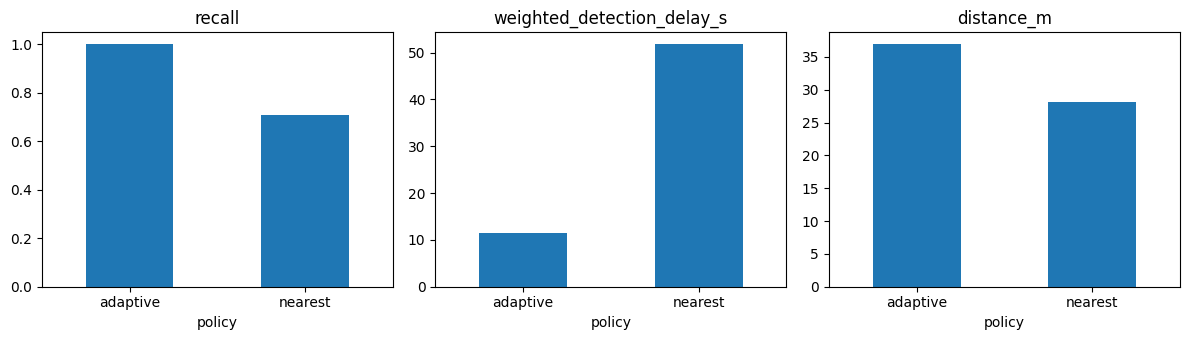

Paired delay gain (s): 40.26
Bootstrap 95% percentile interval: [22.4  57.73]


In [6]:
import matplotlib.pyplot as plt
summary = bench.groupby('policy')[['recall','weighted_detection_delay_s','distance_m']].mean()
fig, ax = plt.subplots(1, 3, figsize = (12, 3.5))
for a, k in zip(ax, summary.columns):
    summary[k].plot.bar(ax = a)
    a.set_title(k)
    a.tick_params(axis = 'x', rotation = 0)
fig.tight_layout()
fig.savefig(out/'planner_only_benchmark.png', dpi = 140)
plt.show()
vals = paired['delay_improvement_s'].to_numpy()
rng = np.random.default_rng(2026)
boots = np.array([rng.choice(vals, len(vals), replace = True).mean() for _ in range(2000)])
print('Paired delay gain (s):', round(vals.mean(), 2))
print('Bootstrap 95% percentile interval:', np.quantile(boots, [.025, .975]).round(2))

### オプション：先行Notebook由来の2D計画比較動画（3D提出動画ではない）

In [7]:
from IPython.display import Video, display
scenario = make_scenario(42)
base = Patrol(scenario, detector,'nearest').run()
adap = Patrol(scenario, detector,'adaptive').run()
assert adap.metrics['coverage'] >= 0.99
video, seconds = render_comparison_video(base, adap, path = out/'planner_only_2D_comparison.mp4', fps = 10, opening_s = 4, outro_s = 7)
print('2D planning visualization (NOT Genesis):', video, seconds,'sec')
display(Video(str(video), embed = True))

2D planning visualization (NOT Genesis): outputs/planner_only_2D_comparison.mp4 67.8 sec
